# Notebook 1 — Implementación desde cero, pruebas y simulación (Problemas 4 y 5)

**Taller 1 · Aprendizaje Automático 2026-2S** · Autor: Juan José Jiménez Maya.

Todos los modelos están en mi módulo `mlcore.py`; aquí solo los importo y los uso.
Los otros dos notebooks importan las mismas clases (no reimplemento ningún modelo).

**Funciones objetivo** (las del notebook de clase), con $\theta=(b,w)$ y $P=\operatorname{diag}(0,1,\dots,1)$:

$$F_{\text{lin}}(\theta)=\frac{1}{2N}\lVert y-\tilde X\theta\rVert_2^2+\frac{\lambda_2}{2}\lVert w\rVert_2^2+\lambda_1\lVert w\rVert_1,$$

$$F_{\text{log}}(\theta)=\frac{1}{S}\sum_n a_n\big[\log(1+e^{z_n})-y_nz_n\big]+\frac{\lambda_2}{2}\lVert w\rVert_2^2,\qquad S=\sum_n a_n .$$

In [1]:
import os
import sys
import time
import json
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression

from mlcore import (OLSRegression, RidgeRegression, LinearRegressionGD, LassoRegression,
                    LogisticRegressionGD, sigmoid, logistic_loss_terms, soft_threshold,
                    numerical_gradient, relative_gradient_error, lasso_kkt_violation, load_model)

RES = Path("resultados")      # aquí guardo tablas y figuras
RES.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.14.7
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


## Problema 4a — Cómo está hecha la implementación

| Clase (`mlcore`) | Algoritmo | Paso $\eta$ | Cuándo para | Máx. iter. |
|---|---|---|---|---|
| `OLSRegression` | `np.linalg.lstsq` sobre $\tilde X$ (si hay columnas repetidas da la solución de norma mínima) | — | fórmula cerrada | — |
| `RidgeRegression` | `np.linalg.solve` de $(\tilde X^\top\tilde X+N\lambda_2P)\theta=\tilde X^\top y$ | — | fórmula cerrada | — |
| `LinearRegressionGD` | descenso por gradiente, L2 opcional | $1/L$, $L=\sigma_{\max}(\tilde X)^2/N+\lambda_2$ | $\lVert\nabla F\rVert_2<$ `tol` | 50 000 |
| `LassoRegression` | gradiente proximal (umbral suave en cada paso) | $1/L$ (la misma $L$) | $\lVert\theta^+-\theta\rVert_2/\eta<$ `tol` (incluye $b$) | 100 000 |
| `LogisticRegressionGD` | descenso por gradiente, L2 y pesos de clase opcionales | $1/L$, $L=\sigma_{\max}(\sqrt{a}\,\tilde X)^2/(4S)+\lambda_2$ | $\lVert\nabla F\rVert_2<$ `tol` | 200 000 |

* $L$ es la constante de Lipschitz del gradiente: con $\eta=1/L$ el objetivo baja en cada paso.
* `accelerate=True` agrega momento (tipo FISTA) para ir más rápido en los problemas 5–7. El criterio de parada no cambia.
* Cada `fit` revisa dimensiones, valores finitos e hiperparámetros, y guarda `history_` (iteración, objetivo, norma de parada),
  `n_iter_`, `termination_` y `converged_`. Si no se pide `warm_start=True`, cada `fit` empieza otra vez en $\theta=0$.

### Historial de convergencia
Uso datos sintéticos estandarizados. Grafico $F(\theta_k)-F^\star$, donde $F^\star$ es el mínimo exacto (Ridge)
o el menor valor que alcanzó alguna de las corridas.

,eta,L,iteraciones,motivo,objetivo final,norma de parada final
modelo,,,,,,
Lineal GD + L2 (λ2=0.1),0.3527,2.8351,141,tol(norma del mapeo de gradiente),0.7408,8.7411e-11
Lineal GD + L2 acelerado,0.3527,2.8351,55,tol(norma del mapeo de gradiente),0.7408,7.7213e-11
Lasso proximal (λ1=0.05),0.3656,2.7351,177,tol(norma del mapeo de gradiente),0.6912,9.8727e-11
Lasso proximal acelerado,0.3656,2.7351,58,tol(norma del mapeo de gradiente),0.6912,8.0793e-11
Logística GD + L2 (λ2=0.01),3.4671,0.2884,47,tol(norma del mapeo de gradiente),0.5084,8.7740e-11
Logística GD + L2 acelerada,3.4671,0.2884,28,tol(norma del mapeo de gradiente),0.5084,7.8063e-11


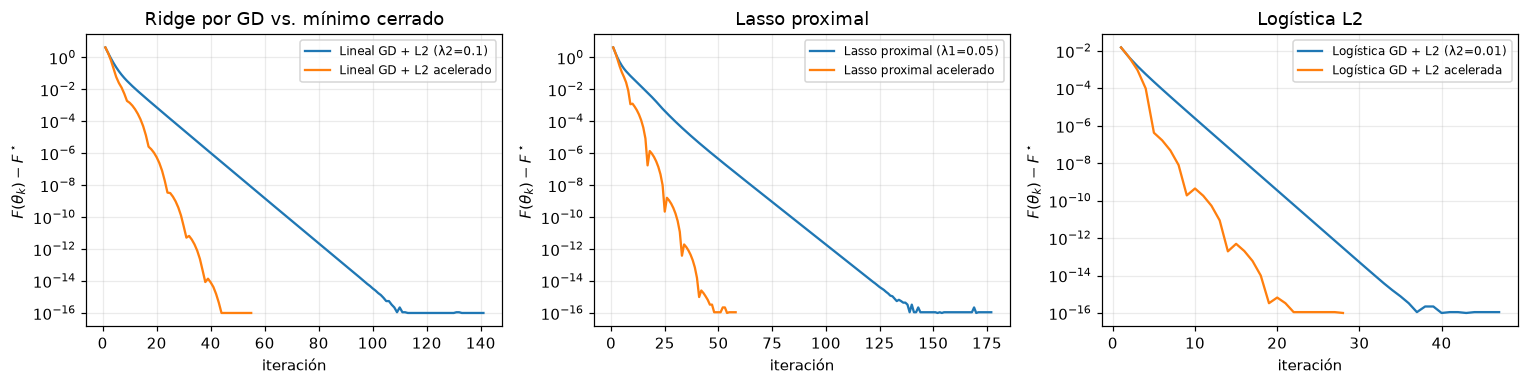

In [2]:
rng = np.random.default_rng(2026)

# datos de regresión: 300 filas, 8 variables con correlación AR(1) rho = 0.5
N_REG, D_REG = 300, 8
C = 0.5 ** np.abs(np.subtract.outer(np.arange(D_REG), np.arange(D_REG)))
X_reg_raw = rng.multivariate_normal(np.zeros(D_REG), C, size=N_REG)
w_true = np.array([1.5, -2.0, 0.0, 0.0, 1.0, 0.0, 0.5, 0.0])
y_reg = 4.0 + X_reg_raw @ w_true + rng.normal(scale=1.0, size=N_REG)
X_reg = StandardScaler().fit_transform(X_reg_raw)

# datos de clasificación: 600 filas, 6 variables
N_CLF, D_CLF = 600, 6
X_clf_raw = rng.normal(size=(N_CLF, D_CLF))
w_clf = np.array([1.2, -0.8, 0.5, 0.0, 0.0, 0.3])
y_clf = (rng.random(N_CLF) < sigmoid(-0.7 + X_clf_raw @ w_clf)).astype(float)
X_clf = StandardScaler().fit_transform(X_clf_raw)

corridas = {
    "Lineal GD + L2 (λ2=0.1)": (LinearRegressionGD(lam2=0.1, tol=1e-10), X_reg, y_reg),
    "Lineal GD + L2 acelerado": (LinearRegressionGD(lam2=0.1, tol=1e-10, accelerate=True), X_reg, y_reg),
    "Lasso proximal (λ1=0.05)": (LassoRegression(lam1=0.05, tol=1e-10), X_reg, y_reg),
    "Lasso proximal acelerado": (LassoRegression(lam1=0.05, tol=1e-10, accelerate=True), X_reg, y_reg),
    "Logística GD + L2 (λ2=0.01)": (LogisticRegressionGD(lam2=0.01, tol=1e-10), X_clf, y_clf),
    "Logística GD + L2 acelerada": (LogisticRegressionGD(lam2=0.01, tol=1e-10, accelerate=True), X_clf, y_clf),
}
registro = []
for nombre in corridas:
    m, X, y = corridas[nombre]
    m.fit(X, y)
    registro.append({"modelo": nombre, "eta": m.eta_, "L": m.lipschitz_, "iteraciones": m.n_iter_,
                     "motivo": m.termination_, "objetivo final": m.history_[-1, 1],
                     "norma de parada final": m.history_[-1, 2]})
registro = pd.DataFrame(registro).set_index("modelo")
display(registro)

# figura: tres paneles (Ridge por GD, Lasso, logística)
F_ridge = RidgeRegression(0.1).fit(X_reg, y_reg).objective(X_reg, y_reg)
nombres = list(corridas)
paneles = [(nombres[0:2], F_ridge, "Ridge por GD vs. mínimo cerrado"),
           (nombres[2:4], None, "Lasso proximal"),
           (nombres[4:6], None, "Logística L2")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (claves, F_ref, titulo) in zip(axes, paneles):
    if F_ref is None:
        F_ref = min(corridas[k][0].history_[:, 1].min() for k in claves)
    for k in claves:
        h = corridas[k][0].history_
        ax.semilogy(h[:, 0], np.maximum(h[:, 1] - F_ref, 1e-16), label=k)
    ax.set(xlabel="iteración", ylabel=r"$F(\theta_k)-F^\star$", title=titulo)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RES / "p4_convergencia.png", bbox_inches="tight")
plt.show()

**Interpretación.** Todas las corridas terminan por tolerancia (ninguna por máximo de iteraciones).
Con $\eta=1/L$ el objetivo baja en cada iteración y en escala log se ve casi como una recta;
la versión acelerada llega a la misma solución en menos iteraciones.
En Ridge la distancia al mínimo exacto (calculado con `solve`) baja hasta el error de redondeo,
así que el gradiente y las ecuaciones normales están bien.

## Problema 4b — Pruebas automáticas

Cada función `test_*` devuelve filas {grupo, prueba, valor, umbral, pasa}. Al final junto todo en una tabla,
la guardo, y un `assert` detiene el notebook si alguna prueba falla.

* **Gradientes:** diferencias centrales con $h=10^{-6}$ en tres puntos $\theta\sim U(-1,1)$, incluyendo $b$ y L2, con
  $\delta_g=\lVert g_a-g_n\rVert/\max(1,\lVert g_a\rVert,\lVert g_n\rVert)$. La parte L1 no se deriva numéricamente;
  Lasso se revisa con las condiciones KKT y con la fórmula del umbral suave en un diseño ortogonal.
* **Estabilidad sin recortar:** $\sigma(z)$ se calcula con $e^{-|z|}$ y la pérdida como
  $\log(1+e^{(1-2y)z})$ usando $\log(1+e^{u})=\max(u,0)+\operatorname{log1p}(e^{-|u|})$.
  El exponente nunca es positivo, así que no hay desbordamiento ni $\log(0)$.

In [3]:
SEED_TESTS = 2026
H = 1e-6


def fila_prueba(grupo, prueba, valor, umbral, pasa=None, menor_o_igual=False):
    """Una fila de la tabla de pruebas. Por defecto la prueba pasa si valor < umbral."""
    if pasa is None:
        if menor_o_igual:
            pasa = bool(valor <= umbral)
        else:
            pasa = bool(valor < umbral)
    return {"grupo": grupo, "prueba": prueba, "valor": float(valor), "umbral": umbral, "pasa": bool(pasa)}


def datos_prueba(rng, n=80, d=4):
    """Datos pequeños para las pruebas: y continua y yb binaria."""
    X = rng.normal(size=(n, d))
    w = rng.normal(size=d)
    y = X @ w + 0.7 + 0.3 * rng.normal(size=n)
    yb = (rng.random(n) < sigmoid(X @ w - 0.5)).astype(float)
    return X, y, yb


def test_gradientes():
    rng = np.random.default_rng(SEED_TESTS)
    X, y, yb = datos_prueba(rng)
    casos = [
        ("lineal MSE/2 (b incluido)", LinearRegressionGD(lam2=0.0), y),
        ("lineal + L2 (lam2=0.3)", LinearRegressionGD(lam2=0.3), y),
        ("Lasso: parte suave (lam1=0.2)", LassoRegression(lam1=0.2), y),
        ("logística", LogisticRegressionGD(lam2=0.0), yb),
        ("logística + L2 (lam2=0.3)", LogisticRegressionGD(lam2=0.3), yb),
        ("logística ponderada + L2", LogisticRegressionGD(lam2=0.3, class_weight="balanced"), yb),
    ]
    filas = []
    for nombre, modelo, yy in casos:
        deltas = []
        for k in range(3):                                   # tres puntos aleatorios
            theta = rng.uniform(-1, 1, size=X.shape[1] + 1)
            g_analitico = modelo.smooth_gradient(X, yy, theta)
            g_numerico = numerical_gradient(lambda t: modelo.smooth_objective(X, yy, t), theta, h=H)
            deltas.append(relative_gradient_error(g_analitico, g_numerico))
        filas.append(fila_prueba("gradiente", f"{nombre}: max delta_g en 3 puntos", max(deltas), 1e-5))
    return filas


def test_sigmoide_perdida():
    z = np.array([-1000, -100, -1, 0, 1, 100, 1000], dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("error")          # si hubiera overflow, saldría un error
        p = sigmoid(z)
        q = sigmoid(-z)
        l1 = logistic_loss_terms(np.ones_like(z), z)
        l0 = logistic_loss_terms(np.zeros_like(z), z)
    filas = []
    sigmoide_ok = np.all(np.isfinite(p)) and np.all((p >= 0) & (p <= 1))
    filas.append(fila_prueba("estabilidad", "sigmoide finita y en [0,1] (7 valores)", 0.0 if sigmoide_ok else 1.0, 0.5))
    filas.append(fila_prueba("estabilidad", "|p(z)+p(-z)-1| máx", np.max(np.abs(p + q - 1)), 1e-15, menor_o_igual=True))
    perdidas_ok = np.all(np.isfinite(l1)) and np.all(np.isfinite(l0))
    filas.append(fila_prueba("estabilidad", "pérdidas finitas (y=0 y y=1)", 0.0 if perdidas_ok else 1.0, 0.5))
    # valores exactos de log(1+e^{-z}) para y=1 (para y=0 es el mismo vector al revés)
    ref1 = np.array([1000.0, 100.0 + np.log1p(np.exp(-100.0)), np.log1p(np.e), np.log(2.0),
                     np.log1p(np.exp(-1.0)), np.exp(-100.0), 0.0])
    ref0 = ref1[::-1]
    err1 = np.max(np.abs(l1 - ref1) / np.maximum(1, ref1))
    err0 = np.max(np.abs(l0 - ref0) / np.maximum(1, ref0))
    filas.append(fila_prueba("estabilidad", "error relativo de la pérdida vs. referencia analítica", max(err1, err0), 1e-14))
    return filas


def test_ols_duplicada():
    rng = np.random.default_rng(SEED_TESTS + 1)
    X, y, _ = datos_prueba(rng, n=60, d=3)
    Xd = np.column_stack([X, X[:, 0]])           # copio la primera columna al final
    m = OLSRegression().fit(Xd, y)
    base = OLSRegression().fit(X, y)
    return [
        fila_prueba("OLS", "columna duplicada: rango detectado = p-1", 0.0 if m.rank_ == Xd.shape[1] else 1.0, 0.5),
        fila_prueba("OLS", "columna duplicada: ||X~^T r||", m.normal_equation_residual(Xd, y), 1e-8),
        fila_prueba("OLS", "predicciones = OLS sin duplicado (máx |dif|)",
                    np.max(np.abs(m.predict(Xd) - base.predict(X))), 1e-9),
        fila_prueba("OLS", "w1 + w_dup = w1 sin duplicado", abs(m.coef_[0] + m.coef_[-1] - base.coef_[0]), 1e-9),
    ]


def test_ridge_duplicada():
    rng = np.random.default_rng(SEED_TESTS + 2)
    X, y, _ = datos_prueba(rng, n=60, d=3)
    Xd = np.column_stack([X, X[:, 0]])
    m = RidgeRegression(lam2=0.5).fit(Xd, y)
    gd = LinearRegressionGD(lam2=0.5, tol=1e-11).fit(Xd, y)
    return [
        fila_prueba("Ridge", "columna duplicada: residuo ecuaciones normales", m.normal_equation_residual(Xd, y), 1e-8),
        fila_prueba("Ridge", "solución única: coeficientes duplicados iguales", abs(m.coef_[0] - m.coef_[-1]), 1e-10),
        fila_prueba("Ridge", "GD coincide con solve (máx |dif theta|)", np.max(np.abs(gd._theta() - m._theta())), 1e-8),
    ]


def diseno_ortogonal(rng, n, d):
    """X centrada con X^T X / N = I (columnas ortogonales entre sí y a la columna de unos)."""
    A = np.column_stack([np.ones(n), rng.normal(size=(n, d))])
    Q, _ = np.linalg.qr(A)
    return np.sqrt(n) * Q[:, 1:]


def test_lasso():
    # caso ortogonal: la solución exacta es el umbral suave de s = X^T y / N
    rng = np.random.default_rng(SEED_TESTS + 3)
    n, d, lam1 = 100, 6, 0.4
    X = diseno_ortogonal(rng, n, d)
    w = np.array([2.0, -1.0, 0.3, 0.0, 0.0, 0.5])
    y = X @ w + 1.5 + 0.5 * rng.normal(size=n)
    m = LassoRegression(lam1=lam1, tol=1e-12).fit(X, y)
    s = X.T @ (y - y.mean()) / n
    w_ref = soft_threshold(s, lam1)
    filas = [
        fila_prueba("Lasso", "ortogonal: X^T X/N = I (máx |dif|)", np.max(np.abs(X.T @ X / n - np.eye(d))), 1e-12),
        fila_prueba("Lasso", "ortogonal: |w - S(s, lam1)| máx", np.max(np.abs(m.coef_ - w_ref)), 1e-9),
        fila_prueba("Lasso", "ortogonal: ceros exactos coinciden",
                    0.0 if np.array_equal(m.coef_ == 0, w_ref == 0) else 1.0, 0.5),
        fila_prueba("Lasso", "ortogonal: violación KKT", lasso_kkt_violation(m, X, y), 1e-8),
    ]
    # caso no ortogonal: dos columnas correlacionadas, se revisa KKT
    Xc, yc, _ = datos_prueba(np.random.default_rng(SEED_TESTS + 4), n=80, d=6)
    Xc[:, 1] = 0.8 * Xc[:, 0] + 0.6 * Xc[:, 1]
    m2 = LassoRegression(lam1=0.15, tol=1e-11).fit(Xc, yc)
    filas.append(fila_prueba("Lasso", "no ortogonal: violación KKT", lasso_kkt_violation(m2, Xc, yc), 1e-8))
    filas.append(fila_prueba("Lasso", "no ortogonal: terminó por tolerancia", 0.0 if m2.converged_ else 1.0, 0.5))
    return filas


def test_persistencia_y_probabilidades():
    rng = np.random.default_rng(SEED_TESTS + 5)
    X, y, yb = datos_prueba(rng, n=120, d=4)
    filas = []
    # guardar en JSON y volver a cargar no debe cambiar las predicciones
    with tempfile.TemporaryDirectory() as carpeta:
        for nombre, modelo, yy in [("Ridge", RidgeRegression(0.1), y),
                                   ("Lasso", LassoRegression(0.05), y),
                                   ("Logística", LogisticRegressionGD(lam2=0.01), yb)]:
            modelo.fit(X, yy)
            ruta = os.path.join(carpeta, f"{nombre}.json")
            modelo.to_json(ruta)
            cargado = load_model(ruta)
            if nombre == "Logística":
                diferencia = np.max(np.abs(modelo.predict_proba(X) - cargado.predict_proba(X)))
            else:
                diferencia = np.max(np.abs(modelo.predict(X) - cargado.predict(X)))
            filas.append(fila_prueba("persistencia", f"{nombre}: predicciones antes/después de guardar",
                                     diferencia, 1e-15, menor_o_igual=True))
    m = LogisticRegressionGD(lam2=0.01).fit(X, yb)
    P = m.predict_proba(X)
    filas.append(fila_prueba("probabilidades", "predict_proba en [0,1]", 0.0 if np.all((P >= 0) & (P <= 1)) else 1.0, 0.5))
    filas.append(fila_prueba("probabilidades", "|suma de columnas - 1| máx", np.max(np.abs(P.sum(1) - 1)), 1e-12))
    # cambiar el umbral tau no debe cambiar las probabilidades ni la log-loss
    p_antes, ll_antes = m.predict_proba(X).copy(), m.log_loss(X, yb)
    decisiones = [m.predict(X, threshold=t) for t in (0.1, 0.5, 0.9)]
    p_despues, ll_despues = m.predict_proba(X), m.log_loss(X, yb)
    filas.append(fila_prueba("probabilidades", "cambiar tau no cambia predict_proba ni log-loss",
                             np.max(np.abs(p_antes - p_despues)) + abs(ll_antes - ll_despues), 0.0, menor_o_igual=True))
    monotono = decisiones[0].sum() >= decisiones[1].sum() >= decisiones[2].sum()
    filas.append(fila_prueba("probabilidades", "decisiones monótonas en tau (#positivos 0.1>=0.5>=0.9)",
                             0.0 if monotono else 1.0, 0.5))
    return filas


def test_reinicio_y_validacion():
    rng = np.random.default_rng(SEED_TESTS + 6)
    X1, y1, _ = datos_prueba(rng, n=60, d=3)
    X2, y2, _ = datos_prueba(rng, n=60, d=3)
    # un segundo fit debe dar lo mismo que un modelo nuevo
    m = LinearRegressionGD(lam2=0.1, tol=1e-10).fit(X1, y1)
    m.fit(X2, y2)
    nuevo = LinearRegressionGD(lam2=0.1, tol=1e-10).fit(X2, y2)
    filas = [fila_prueba("estado", "segunda llamada a fit reinicializa (mismas iteraciones y theta)",
                         np.max(np.abs(m._theta() - nuevo._theta())) + abs(m.n_iter_ - nuevo.n_iter_), 0.0,
                         menor_o_igual=True)]
    # con warm_start=True el segundo ajuste parte de la solución anterior y necesita menos iteraciones
    caliente = LinearRegressionGD(lam2=0.1, tol=1e-10, warm_start=True).fit(X2, y2)
    n_primero = caliente.n_iter_
    caliente.fit(X2, y2)
    filas.append(fila_prueba("estado", "warm_start=True parte de la solución previa (iteraciones 2º ajuste)",
                             caliente.n_iter_, n_primero))
    # entradas malas: todas deben lanzar ValueError
    entradas_malas = [
        lambda: OLSRegression().fit(np.array([1.0, 2.0]), np.array([1.0, 2.0])),           # X en 1D
        lambda: OLSRegression().fit(np.array([[1.0], [np.nan]]), np.array([1.0, 2.0])),    # NaN
        lambda: OLSRegression().fit(np.ones((3, 1)), np.ones(2)),                          # tamaños distintos
        lambda: RidgeRegression(lam2=-1).fit(np.ones((3, 1)), np.ones(3)),                 # lambda negativo
        lambda: LassoRegression(lam1=-0.1).fit(np.ones((3, 1)), np.ones(3)),
        lambda: LogisticRegressionGD().fit(np.ones((3, 1)), np.array([0, 1, 2.0])),        # etiqueta 2
        lambda: LinearRegressionGD(max_iter=0).fit(np.ones((3, 1)), np.ones(3)),
        lambda: RidgeRegression(0.1).fit(np.ones((3, 2)), np.ones(3)).predict(np.ones((2, 3))),  # columnas
    ]
    errores = 0
    for f in entradas_malas:
        try:
            f()
        except ValueError:
            errores += 1
    filas.append(fila_prueba("validación", "entradas inválidas rechazadas con ValueError (de 8)",
                             len(entradas_malas) - errores, 0.0, menor_o_igual=True))
    return filas

In [4]:
filas = []
for test in [test_gradientes, test_sigmoide_perdida, test_ols_duplicada, test_ridge_duplicada,
             test_lasso, test_persistencia_y_probabilidades, test_reinicio_y_validacion]:
    filas += test()
pruebas = pd.DataFrame(filas)
pruebas.to_csv(RES / "p4_pruebas_numericas.csv", index=False)
display(pruebas)
print(f"Pruebas superadas: {pruebas.pasa.sum()} de {len(pruebas)}")
assert pruebas.pasa.all()

,grupo,prueba,valor,umbral,pasa
0,gradiente,lineal MSE/2 (b incluido): max delta_g en 3 pu...,1.0325e-10,1.0000e-05,True
1,gradiente,lineal + L2 (lam2=0.3): max delta_g en 3 puntos,1.2815e-10,1.0000e-05,True
2,gradiente,Lasso: parte suave (lam1=0.2): max delta_g en ...,2.5133e-10,1.0000e-05,True
3,gradiente,logística: max delta_g en 3 puntos,1.5857e-10,1.0000e-05,True
4,gradiente,logística + L2 (lam2=0.3): max delta_g en 3 pu...,2.2341e-10,1.0000e-05,True
5,gradiente,logística ponderada + L2: max delta_g en 3 puntos,1.8458e-10,1.0000e-05,True
6,estabilidad,"sigmoide finita y en [0,1] (7 valores)",0.0000e+00,5.0000e-01,True
7,estabilidad,|p(z)+p(-z)-1| máx,0.0000e+00,1.0000e-15,True
8,estabilidad,pérdidas finitas (y=0 y y=1),0.0000e+00,5.0000e-01,True
9,estabilidad,error relativo de la pérdida vs. referencia an...,0.0000e+00,1.0000e-14,True


Pruebas superadas: 33 de 33


In [5]:
# tabla de la sigmoide y la pérdida en valores extremos de z
z = np.array([-1000, -100, -1, 0, 1, 100, 1000.0])
tabla_z = pd.DataFrame({"z": z, "sigma(z)": sigmoid(z), "1-sigma(z) = sigma(-z)": sigmoid(-z),
                        "pérdida y=1": logistic_loss_terms(np.ones(7), z),
                        "pérdida y=0": logistic_loss_terms(np.zeros(7), z)})
display(tabla_z.set_index("z"))

,sigma(z),1-sigma(z) = sigma(-z),pérdida y=1,pérdida y=0
z,,,,
-1000.0,0.0000e+00,1.0000e+00,1.0000e+03,0.0000e+00
-100.0,3.7201e-44,1.0000e+00,1.0000e+02,3.7201e-44
-1.0,2.6894e-01,7.3106e-01,1.3133e+00,3.1326e-01
0.0,5.0000e-01,5.0000e-01,6.9315e-01,6.9315e-01
1.0,7.3106e-01,2.6894e-01,3.1326e-01,1.3133e+00
100.0,1.0000e+00,3.7201e-44,3.7201e-44,1.0000e+02
1000.0,1.0000e+00,0.0000e+00,0.0000e+00,1.0000e+03


**Interpretación.** Los errores de gradiente son del orden de $10^{-10}$, muy por debajo de la meta $10^{-5}$.
Con la columna duplicada, OLS detecta el rango deficiente, cumple $\tilde X^\top r=0$ y conserva las
predicciones (solo la suma de los dos coeficientes queda determinada). Ridge da una solución única con el
mismo coeficiente para las dos copias. Lasso coincide con el umbral suave en el diseño ortogonal y cumple
KKT en el diseño correlacionado.

## Problema 4c — Comparación con scikit-learn

### Equivalencia de parámetros

scikit-learn escribe los objetivos de otra forma, así que hay que traducir $\lambda$ a `alpha` o `C`:

| Estimador | Objetivo que minimiza scikit-learn | Multiplico mi objetivo por | Equivalencia | Intercepto |
|---|---|---|---|---|
| `LinearRegression` | $\lVert y-Xw-b\rVert^2$ | $2N$ | sin penalización | no penalizado |
| `Ridge(alpha)` | $\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert^2$ | $2N$ | $\alpha=N\lambda_2$ | no penalizado |
| `Lasso(alpha)` | $\frac1{2N}\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert_1$ | $1$ | $\alpha=\lambda_1$ | no penalizado |
| `LogisticRegression(C)` | $C\sum_n s_n\ell_n+\frac12\lVert w\rVert^2$ | $1/(S\lambda_2)$ | $C=1/(S\lambda_2)$; sin pesos $S=N$ | no penalizado |
| idem, `class_weight='balanced'` | $s_n=N/(2N_{y_n})$ | $1/(S\lambda_2)$ | $S=\sum_n s_n=N$ ⇒ $C=1/(N\lambda_2)$ | no penalizado |
| sin penalizar | `C=np.inf` | — | $\lambda_2=0$ | — |

Como `alpha` de Ridge y `C` dependen de $N$, **recalculo la equivalencia cada vez que cambia el número de filas**:
abajo repito todo con $N$ y con $N/2$. Mido la diferencia relativa de objetivo (evaluando **mi** objetivo en los
dos vectores de parámetros) y el error relativo de predicciones (de probabilidades en logística).

In [6]:
def contraste(nombre, propio, sk, X, y, clasificacion=False):
    propio.fit(X, y)
    sk.fit(X, y)
    if np.ndim(sk.intercept_) == 0:
        theta_sk = np.r_[sk.intercept_, np.ravel(sk.coef_)]
    else:
        theta_sk = np.r_[sk.intercept_[0], np.ravel(sk.coef_)]
    F_propio = propio.objective(X, y)
    F_sk = propio.objective(X, y, theta_sk)
    if clasificacion:
        a = propio.predict_proba(X)[:, 1]
        b = sk.predict_proba(X)[:, 1]
        acuerdo = float(np.mean(propio.predict(X) == sk.predict(X)))
    else:
        a = propio.predict(X)
        b = sk.predict(X)
        acuerdo = np.nan
    return {"modelo": nombre, "N": len(y), "F propio": F_propio, "F sklearn (obj. propio)": F_sk,
            "dif. rel. objetivo": abs(F_propio - F_sk) / max(1, abs(F_sk)),
            "error rel. predicción/prob.": np.linalg.norm(a - b) / np.linalg.norm(b),
            "acuerdo etiquetas": acuerdo,
            "máx |dif coef|": np.max(np.abs(propio._theta() - theta_sk)),
            "iter. propio": propio.n_iter_}


LAM2, LAM1, LAM2_LOG = 0.1, 0.05, 0.01
filas = []
for n in (N_REG, N_REG // 2):
    Xr = StandardScaler().fit_transform(X_reg_raw[:n])     # cada N tiene su propio escalador
    yr = y_reg[:n]
    filas.append(contraste("OLS (lstsq)", OLSRegression(), LinearRegression(), Xr, yr))
    filas.append(contraste(f"Ridge solve λ2={LAM2} | alpha=N·λ2={n*LAM2:g}", RidgeRegression(LAM2),
                           Ridge(alpha=n * LAM2), Xr, yr))
    filas.append(contraste(f"Ridge GD λ2={LAM2} | alpha={n*LAM2:g}", LinearRegressionGD(lam2=LAM2, tol=1e-11),
                           Ridge(alpha=n * LAM2), Xr, yr))
    filas.append(contraste(f"Lasso prox λ1={LAM1} | alpha={LAM1}", LassoRegression(LAM1, tol=1e-11),
                           Lasso(alpha=LAM1, tol=1e-12, max_iter=100_000), Xr, yr))
for n in (N_CLF, N_CLF // 2):
    Xc = StandardScaler().fit_transform(X_clf_raw[:n])
    yc = y_clf[:n]
    C_eq = 1 / (n * LAM2_LOG)
    filas.append(contraste("Logística sin penalizar | C=inf", LogisticRegressionGD(tol=1e-10),
                           LogisticRegression(C=np.inf, tol=1e-12, max_iter=10_000), Xc, yc, True))
    filas.append(contraste(f"Logística L2 λ2={LAM2_LOG} | C=1/(Nλ2)={C_eq:.4g}",
                           LogisticRegressionGD(lam2=LAM2_LOG, tol=1e-10),
                           LogisticRegression(C=C_eq, tol=1e-12, max_iter=10_000), Xc, yc, True))
    filas.append(contraste(f"Logística L2 balanceada | C={C_eq:.4g}",
                           LogisticRegressionGD(lam2=LAM2_LOG, class_weight="balanced", tol=1e-10),
                           LogisticRegression(C=C_eq, class_weight="balanced", tol=1e-12, max_iter=10_000),
                           Xc, yc, True))
comparacion = pd.DataFrame(filas)
comparacion["meta < 1e-4"] = (comparacion["dif. rel. objetivo"] < 1e-4) & (comparacion["error rel. predicción/prob."] < 1e-4)
comparacion.to_csv(RES / "p4_contraste_sklearn.csv", index=False)
display(comparacion)
assert comparacion["meta < 1e-4"].all()

,modelo,N,F propio,F sklearn (obj. propio),dif. rel. objetivo,error rel. predicción/prob.,acuerdo etiquetas,máx |dif coef|,iter. propio,meta < 1e-4
0,OLS (lstsq),300,0.4481,0.4481,0.0000e+00,7.4244e-16,NaN,2.1094e-15,0,True
1,Ridge solve λ2=0.1 | alpha=N·λ2=30,300,0.7408,0.7408,0.0000e+00,2.9804e-16,NaN,8.8818e-16,0,True
2,Ridge GD λ2=0.1 | alpha=30,300,0.7408,0.7408,1.1102e-16,2.4288e-12,NaN,8.9237e-12,155,True
3,Lasso prox λ1=0.05 | alpha=0.05,300,0.6912,0.6912,0.0000e+00,3.5136e-12,NaN,1.7127e-11,196,True
4,OLS (lstsq),150,0.4488,0.4488,0.0000e+00,1.6232e-15,NaN,5.3846e-15,0,True
5,Ridge solve λ2=0.1 | alpha=N·λ2=15,150,0.7155,0.7155,1.1102e-16,2.8572e-16,NaN,8.8818e-16,0,True
6,Ridge GD λ2=0.1 | alpha=15,150,0.7155,0.7155,0.0000e+00,2.7230e-12,NaN,1.2697e-11,153,True
7,Lasso prox λ1=0.05 | alpha=0.05,150,0.6839,0.6839,0.0000e+00,3.4505e-12,NaN,1.6463e-11,173,True
8,Logística sin penalizar | C=inf,600,0.4980,0.4980,1.1102e-16,4.4834e-10,1.0,7.0516e-10,57,True
9,Logística L2 λ2=0.01 | C=1/(Nλ2)=0.1667,600,0.5084,0.5084,0.0000e+00,9.6689e-09,1.0,1.6417e-08,47,True


**Caso sin solución única.** Si duplico una columna, Lasso tiene infinitas soluciones: solo la suma $w_1+w_2$
queda determinada. scikit-learn (descenso por coordenadas) tiende a darle más peso a una copia, y mi gradiente
proximal, que empieza en cero y trata las dos columnas igual, lo reparte por mitades. **Comparar coeficientes
uno a uno daría una falsa alarma**; lo correcto es comparar el objetivo, las predicciones y KKT.

In [7]:
Xd = np.column_stack([X_reg, X_reg[:, 0]])
prop = LassoRegression(LAM1, tol=1e-11).fit(Xd, y_reg)
skd = Lasso(alpha=LAM1, tol=1e-12, max_iter=100_000).fit(Xd, y_reg)
theta_sk = np.r_[skd.intercept_, skd.coef_]
tabla_dup = pd.DataFrame({
    "w1 (col. 1)": [prop.coef_[0], skd.coef_[0]],
    "w_dup (copia)": [prop.coef_[-1], skd.coef_[-1]],
    "w1 + w_dup": [prop.coef_[0] + prop.coef_[-1], skd.coef_[0] + skd.coef_[-1]],
    "objetivo propio": [prop.objective(Xd, y_reg), prop.objective(Xd, y_reg, theta_sk)],
    "violación KKT": [lasso_kkt_violation(prop, Xd, y_reg), np.nan]},
    index=["propio (proximal)", "sklearn (coordenadas)"])
display(tabla_dup)
print("error relativo de predicciones:",
      np.linalg.norm(prop.predict(Xd) - skd.predict(Xd)) / np.linalg.norm(skd.predict(Xd)))

,w1 (col. 1),w_dup (copia),w1 + w_dup,objetivo propio,violación KKT
propio (proximal),0.7331,0.7331,1.4663,0.6912,5.5632e-12
sklearn (coordenadas),0.5765,0.8897,1.4663,0.6912,NaN


error relativo de predicciones: 3.5994651827511006e-12


**Interpretación del contraste.** En todos los casos la diferencia relativa de objetivo y el error relativo de
predicciones o probabilidades quedan muy por debajo de $10^{-4}$, con $N$ y con $N/2$ filas. En logística comparo
probabilidades, no solo etiquetas. Las diferencias que quedan vienen de que cada método para con un criterio distinto,
no de que los objetivos sean distintos.

## Problema 5 — Simulación de sesgo, varianza y selección

**Diseño.** $N=120$, $D=20$, $M=1000$, cuatro bloques de cinco variables con varianza 1 y correlación
$\rho\in\{0,\ 0.9\}$ dentro de cada bloque. $w^\star_1=3$, $w^\star_6=-2$, $w^\star_{11}=1.5$, $w^\star_{16}=-1$
y el resto cero; $\sigma^2=1$; $R=40$ respuestas con $X$ y $X_*$ fijas. Sin intercepto (`fit_intercept=False`)
y **sin escalador**. De la semilla maestra 2026 saco subsemillas (diseño, auditoría y cada ruido) y las guardo.

Modelos: OLS (`lstsq`), Ridge (`solve`) y Lasso (gradiente proximal acelerado, `tol=1e-8`), con
$\Lambda=\{10^{-3},10^{-2},10^{-1},1,10\}$.

In [8]:
N, D, M, R, SIGMA = 120, 20, 1000, 40, 1.0
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
RHOS = [0.0, 0.9]
w_star = np.zeros(D)
w_star[[0, 5, 10, 15]] = [3.0, -2.0, 1.5, -1.0]
S_STAR = {0, 5, 10, 15}             # posiciones (desde 0) de las variables relevantes
BLOQUE = np.repeat(np.arange(4), 5)  # bloque de cada variable: 0,0,0,0,0,1,1,...
TOL_SEL = 1e-8                       # tolerancia fija para decir que un coeficiente no es cero

maestra = np.random.default_rng(2026)
subsemillas = {}
for rho in RHOS:
    s = maestra.integers(0, 2**32 - 1, size=2 + R)
    subsemillas[rho] = {"diseño_X": int(s[0]), "auditoría_X*": int(s[1]),
                        "ruidos": [int(v) for v in s[2:]]}
with open(RES / "p5_subsemillas.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in subsemillas.items()}, f, indent=1)


def matriz_covarianza(rho):
    bloque = (1 - rho) * np.eye(5) + rho * np.ones((5, 5))
    return np.kron(np.eye(4), bloque)       # 4 bloques en la diagonal


def generar_escenario(rho):
    """Devuelve X (N x D), X* (M x D) y las R respuestas Y (R x N)."""
    Lc = np.linalg.cholesky(matriz_covarianza(rho))
    X = np.random.default_rng(subsemillas[rho]["diseño_X"]).normal(size=(N, D)) @ Lc.T
    Xs = np.random.default_rng(subsemillas[rho]["auditoría_X*"]).normal(size=(M, D)) @ Lc.T
    respuestas = []
    for semilla in subsemillas[rho]["ruidos"]:
        ruido = SIGMA * np.random.default_rng(semilla).normal(size=N)
        respuestas.append(X @ w_star + ruido)
    return X, Xs, np.stack(respuestas)


tabla_semillas = pd.DataFrame({rho: {"diseño_X": v["diseño_X"], "auditoría_X*": v["auditoría_X*"],
                                     "ruido r=1": v["ruidos"][0], "ruido r=40": v["ruidos"][-1]}
                               for rho, v in subsemillas.items()}).T
display(tabla_semillas.rename_axis("rho"))

,diseño_X,auditoría_X*,ruido r=1,ruido r=40
rho,,,,
0.0,3658676649,768519171,113462462,2258366144
0.9,393421429,1850753207,1163014937,1347848041


In [9]:
def ajustar(modelo, lam, X, y):
    if modelo == "OLS":
        m = OLSRegression(fit_intercept=False)
    elif modelo == "Ridge":
        m = RidgeRegression(lam2=lam, fit_intercept=False)
    else:
        m = LassoRegression(lam1=lam, fit_intercept=False, accelerate=True, tol=1e-8, max_iter=200_000)
    with warnings.catch_warnings():
        warnings.simplefilter("error", RuntimeWarning)   # si no converge, que salga un error
        return m.fit(X, y)


sim = []
coefs = {}
t_sim = time.time()
for rho in RHOS:
    X, Xs, Y = generar_escenario(rho)
    f_star = Xs @ w_star                                   # función verdadera en X*
    for modelo, lams in [("OLS", [0.0]), ("Ridge", LAMBDAS), ("Lasso", LAMBDAS)]:
        for lam in lams:
            W = np.stack([ajustar(modelo, lam, X, Y[r]).coef_ for r in range(R)])   # R x D
            F = W @ Xs.T                                     # predicciones R x M
            fbar = F.mean(0)                                 # promedio sobre réplicas
            B2 = np.mean((fbar - f_star) ** 2)
            V = np.mean(np.mean((F - fbar) ** 2, axis=0))    # con 1/R
            Ef = np.mean((F - f_star) ** 2)
            coefs[(rho, modelo, lam)] = W
            sim.append({"rho": rho, "modelo": modelo, "lambda": lam, "B2": B2, "V": V, "E_f": Ef,
                        "|E_f-(B2+V)|": abs(Ef - B2 - V), "E_pred = E_f + σ²": Ef + SIGMA ** 2,
                        "B2 corregido = B2 - V/(R-1)": B2 - V / (R - 1),
                        "||w̄-w*||²": np.sum((W.mean(0) - w_star) ** 2)})
sim = pd.DataFrame(sim)
sim.to_csv(RES / "p5_sesgo_varianza.csv", index=False)
print(f"Ajustes: {len(sim)} configuraciones x {R} réplicas en {time.time() - t_sim:.1f} s")
assert sim["|E_f-(B2+V)|"].max() < 1e-10
display(sim.set_index(["rho", "modelo", "lambda"]))

Ajustes: 22 configuraciones x 40 réplicas en 1.2 s


B2       V      E_f  |E_f-(B2+V)|  E_pred = E_f + σ²  B2 corregido = B2 - V/(R-1)  ||w̄-w*||²
rho modelo lambda                                                                                                    
0.0 OLS    0.000    0.0068  0.1946   0.2014    2.7756e-17             1.2014                       0.0018      0.0067
    Ridge  0.001    0.0067  0.1940   0.2008    0.0000e+00             1.2008                       0.0017      0.0066
           0.010    0.0081  0.1891   0.1973    2.7756e-17             1.1973                       0.0033      0.0082
           0.100    0.1940  0.1498   0.3438    2.7756e-17             1.3438                       0.1902      0.1994
           1.000    4.3621  0.0385   4.4006    5.5511e-16             5.4006                       4.3611      4.4408
           10.000  13.2405  0.0013  13.2418    5.9978e-16            14.2418                      13.2405     13.4211
    Lasso  0.001    0.0067  0.1913   0.1979    2.7756e-17             1.1979                       0.0018      0.0065
           0.010    0.0058  0.1638   0.1697    2.7756e-17             1.1697                       0.0016      0.0058
           0.100    0.0432  0.0532   0.0963    1.3878e-17             1.0963                       0.0418      0.0447
           1.000    4.6505  0.0321   4.6827    6.1756e-16             5.6827                       4.6497      4.7815
           10.000  16.0484  0.0000  16.0484    0.0000e+00            17.0484                      16.0484     16.2500
0.9 OLS    0.000    0.0044  0.1956   0.2000    2.7756e-17             1.2000                      -0.0006      0.0482
    Ridge  0.001    0.0034  0.1913   0.1947    2.7756e-17             1.1947                      -0.0015      0.0357
           0.010    0.0159  0.1601   0.1759    0.0000e+00             1.1759                       0.0118      0.1437
           0.100    0.3843  0.0646   0.4490    1.3878e-17             1.4490                       0.3827      3.7163
           1.000    1.4542  0.0209   1.4751    1.1796e-16             2.4751                       1.4537     10.8353
           10.000   7.2624  0.0027   7.2651    1.1375e-15             8.2651                       7.2623     14.0779
    Lasso  0.001    0.0036  0.1864   0.1900    2.7756e-17             1.1900                      -0.0012      0.0387
           0.010    0.0046  0.1232   0.1278    1.3878e-17             1.1278                       0.0014      0.0404
           0.100    0.0496  0.0541   0.1037    6.9389e-18             1.1037                       0.0482      0.2732
           1.000    2.7618  0.0323   2.7941    6.2450e-17             3.7941                       2.7610      3.2932
           10.000  15.7579  0.0000  15.7579    3.5527e-15            16.7579                      15.7579     16.2500

**Por qué la descomposición es exacta.** Para cada punto $m$:
$\frac1R\sum_r(\hat f_{rm}-f^\star_m)^2=(\bar f_m-f^\star_m)^2+\frac1R\sum_r(\hat f_{rm}-\bar f_m)^2$,
porque el término cruzado $\frac2R\sum_r(\hat f_{rm}-\bar f_m)(\bar f_m-f^\star_m)$ es cero (las desviaciones respecto al
promedio suman cero). Esto solo cierra exacto si uso $1/R$; con $1/(R-1)$ la suma no daría. La columna
`|E_f-(B2+V)|` es solo error de redondeo.
$\hat E_f$ mide el error frente a la **función** $f^\star$. Para una respuesta nueva $y_*=f^\star(x_*)+\varepsilon_*$
el ruido nuevo no se puede predecir, así que el error esperado es $\hat E_f+\sigma^2$.

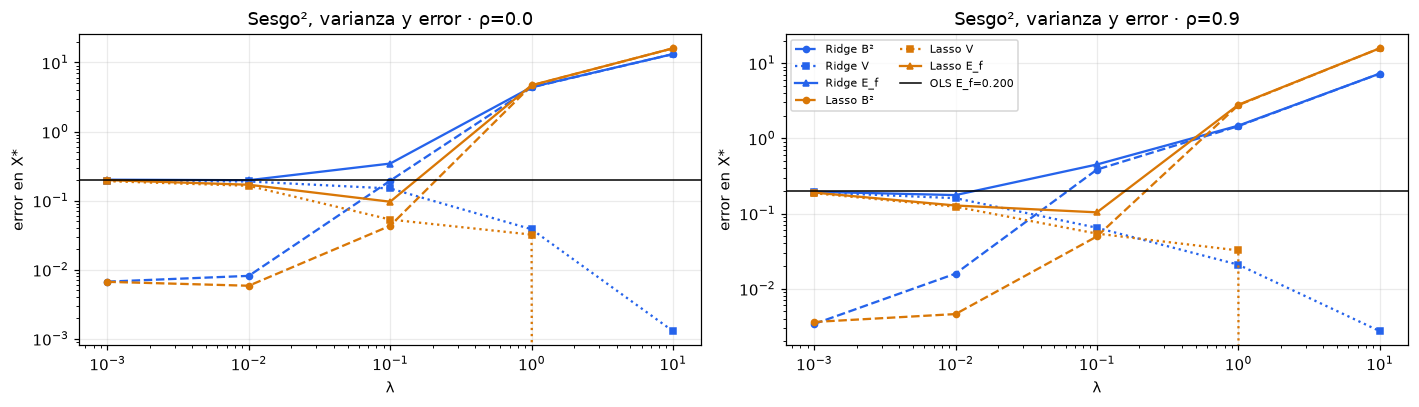

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, rho in zip(axes, RHOS):
    s = sim[sim.rho == rho]
    ols = s[s.modelo == "OLS"].iloc[0]
    for modelo, color in [("Ridge", "#2563eb"), ("Lasso", "#d97706")]:
        t = s[s.modelo == modelo]
        ax.plot(t["lambda"], t.B2, "--o", color=color, label=f"{modelo} B²", ms=4)
        ax.plot(t["lambda"], t.V, ":s", color=color, label=f"{modelo} V", ms=4)
        ax.plot(t["lambda"], t.E_f, "-^", color=color, label=f"{modelo} E_f", ms=4)
    ax.axhline(ols.E_f, color="k", lw=1, label=f"OLS E_f={ols.E_f:.3f}")
    ax.set(xscale="log", yscale="log", xlabel="λ", ylabel="error en X*",
           title=f"Sesgo², varianza y error · ρ={rho}")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(RES / "p5_sesgo_varianza.png", bbox_inches="tight")
plt.show()

**Interpretación.** Al subir $\lambda$ la varianza $\hat V$ baja (OLS ≈ 0.195 → Ridge $\lambda=10$: 0.001) y el sesgo²
$\hat B^2$ sube. El error total $\hat E_f$ es mínimo en un valor intermedio: Lasso $\lambda_1=0.1$ (0.096 con ρ=0 y
0.104 con ρ=0.9, frente a 0.20 de OLS) y Ridge $\lambda_2=0.01$ (0.197 y 0.176). Con $\lambda\ge1$ domina el sesgo.

*Nota:* aunque OLS es insesgado, su $\hat B^2$ sale ≈0.004–0.007 porque $\bar f_m$ es un promedio de solo 40 réplicas
y también tiene ruido ($\mathbb E[\hat B^2]=B^2+V/R$). La columna `B2 corregido` $=\hat B^2-\hat V/(R-1)$ quita ese efecto.

### Ridge: media y covarianza empíricas contra las fórmulas teóricas
Con $b=0$ y $X$ fija, $A=(X^\top X+N\lambda_2I)^{-1}$ (la aplico con `solve`, sin invertir):
$\mathbb E[\hat w]=AX^\top Xw^\star$ y $\operatorname{Cov}(\hat w)=\sigma^2AX^\top XA$.
Con solo 40 réplicas la media empírica tiene un error del orden de $\sqrt{\operatorname{tr}\,\mathrm{Cov}/R}$, y la
covarianza empírica un error relativo esperado grande (≈0.7 en dimensión 20), así que comparo contra esas referencias.

In [11]:
teoria = []
for rho in RHOS:
    X, Xs, Y = generar_escenario(rho)
    G = X.T @ X
    for lam in LAMBDAS:
        Amat = G + N * lam * np.eye(D)
        media_teo = np.linalg.solve(Amat, G @ w_star)
        AG = np.linalg.solve(Amat, G)                         # A X^T X
        cov_teo = SIGMA ** 2 * np.linalg.solve(Amat, AG.T).T   # A X^T X A
        W = coefs[(rho, "Ridge", lam)]
        media_emp = W.mean(0)
        cov_emp = np.cov(W.T, ddof=1)
        error_mc = np.sqrt(np.trace(cov_teo) / R)
        B2_teo = np.mean((Xs @ (media_teo - w_star)) ** 2)
        V_teo = np.mean(np.einsum("md,de,me->m", Xs, cov_teo, Xs))
        fila = sim[(sim.rho == rho) & (sim.modelo == "Ridge") & (sim["lambda"] == lam)].iloc[0]
        err_cov_esperado = np.sqrt((np.trace(cov_teo @ cov_teo) + np.trace(cov_teo) ** 2) / (R - 1)) / np.linalg.norm(cov_teo)
        teoria.append({"rho": rho, "lambda": lam,
                       "||media emp - teórica||": np.linalg.norm(media_emp - media_teo),
                       "error MC esperado": error_mc,
                       "err. rel. Cov (Frobenius)": np.linalg.norm(cov_emp - cov_teo) / np.linalg.norm(cov_teo),
                       "err. rel. Cov esperado (MC)": err_cov_esperado,
                       "B² teórico": B2_teo, "B² emp.": fila.B2,
                       "V teórica·(R-1)/R": V_teo * (R - 1) / R, "V emp.": fila.V})
teoria = pd.DataFrame(teoria)
teoria.to_csv(RES / "p5_ridge_teoria_vs_empirica.csv", index=False)
display(teoria.set_index(["rho", "lambda"]))

||media emp - teórica||  error MC esperado  err. rel. Cov (Frobenius)  err. rel. Cov esperado (MC)  B² teórico  B² emp.  V teórica·(R-1)/R  V emp.
rho lambda                                                                                                                                                    
0.0 0.001                    0.0815             0.0703                     0.7281                       0.6729  2.6887e-05   0.0067             0.1927  0.1940
    0.010                    0.0806             0.0694                     0.7303                       0.6755  2.6077e-03   0.0081             0.1879  0.1891
    0.100                    0.0720             0.0618                     0.7470                       0.6958  1.9811e-01   0.1940             0.1490  0.1498
    1.000                    0.0367             0.0315                     0.7614                       0.7329  4.3930e+00   4.3621             0.0387  0.0385
    10.000                   0.0067             0.0058                     0.6976                       0.6957  1.3253e+01  13.2405             0.0013  0.0013
0.9 0.001                    0.2158             0.1937                     0.6394                       0.6157  2.8729e-04   0.0034             0.1856  0.1913
    0.010                    0.1882             0.1735                     0.6637                       0.6337  2.0954e-02   0.0159             0.1554  0.1601
    0.100                    0.0904             0.0905                     0.7250                       0.6730  3.9736e-01   0.3843             0.0653  0.0646
    1.000                    0.0170             0.0200                     0.6780                       0.6876  1.4545e+00   1.4542             0.0236  0.0209
    10.000                   0.0027             0.0046                     0.3303                       0.4099  7.2584e+00   7.2624             0.0032  0.0027

**Interpretación.** La distancia entre la media empírica y la teórica es del mismo tamaño que el error Monte Carlo
esperado, y la diferencia de covarianzas también coincide con su referencia. $B^2$ y $V$ teóricos reproducen los
empíricos. Las fórmulas del problema 1c se confirman.

### Sesgo y varianza en las direcciones propias de $X^\top X$ (contraste con el problema 1c)
Con $X^\top X=\sum_k d_kv_kv_k^\top$: sesgo$_k=-\frac{N\lambda_2}{d_k+N\lambda_2}\langle v_k,w^\star\rangle$ y
varianza$_k=\sigma^2\frac{d_k}{(d_k+N\lambda_2)^2}$. Muestro la dirección con el autovalor más pequeño y la del más grande.

In [12]:
filas = []
for rho in RHOS:
    X, _, _ = generar_escenario(rho)
    d, Vk = np.linalg.eigh(X.T @ X)          # autovalores de menor a mayor
    proy = Vk.T @ w_star
    for lam in [0.0] + LAMBDAS:
        k = N * lam
        for etiqueta, idx in [("d_min", 0), ("d_max", D - 1)]:
            filas.append({"rho": rho, "lambda": lam, "dirección": etiqueta, "d_k": d[idx],
                          "sesgo_k": -k / (d[idx] + k) * proy[idx],
                          "var_k": SIGMA ** 2 * d[idx] / (d[idx] + k) ** 2})
direcciones = pd.DataFrame(filas)
display(direcciones.pivot_table(index=["rho", "lambda"], columns="dirección",
                                values=["d_k", "sesgo_k", "var_k"]).round(5))
for rho in RHOS:
    X, _, _ = generar_escenario(rho)
    print(f"rho={rho}: número de condición de X^T X = {np.linalg.cond(X.T @ X):.1f}")

d_k              sesgo_k           var_k            
dirección      d_max    d_min       d_max   d_min   d_max       d_min
rho lambda                                                           
0.0 0.000   223.0865  49.7054  0.0000e+00  0.0000  0.0045  2.0120e-02
    0.001   223.0865  49.7054  8.0000e-05 -0.0025  0.0045  2.0020e-02
    0.010   223.0865  49.7054  7.8000e-04 -0.0242  0.0044  1.9180e-02
    0.100   223.0865  49.7054  7.4700e-03 -0.1997  0.0040  1.3050e-02
    1.000   223.0865  49.7054  5.1190e-02 -0.7261  0.0019  1.7300e-03
    10.000  223.0865  49.7054  1.2342e-01 -0.9861  0.0001  3.0000e-05
0.9 0.000   746.6504   5.1450  0.0000e+00  0.0000  0.0013  1.9436e-01
    0.001   746.6504   5.1450  2.4000e-04  0.0400  0.0013  1.8560e-01
    0.010   746.6504   5.1450  2.4400e-03  0.3323  0.0013  1.2780e-01
    0.100   746.6504   5.1450  2.4090e-02  1.2297  0.0013  1.7500e-02
    1.000   746.6504   5.1450  2.1088e-01  1.6847  0.0010  3.3000e-04
    10.000  746.6504   5.1450  9.3883e-01  1.7494  0.0002  0.0000e+00

rho=0.0: número de condición de X^T X = 4.5
rho=0.9: número de condición de X^T X = 145.1


**Contraste con 1c.** Con ρ=0.9 el número de condición de $X^\top X$ es ≈145 (≈4.5 con ρ=0). En la dirección de
autovalor pequeño ($d_{\min}\approx5$) OLS tiene varianza 0.194; con λ=0.01 baja a 0.128 a cambio de un sesgo de 0.33.
En la dirección grande ($d_{\max}\approx747$) el sesgo casi no aparece. O sea: Ridge "frena" sobre todo las direcciones
inestables. Pero no sirve para cualquier λ: con λ=10 la varianza es casi cero y el error es 36–80 veces el de OLS.

### Lasso: selección y recuperación del soporte
Antes de ver resultados fijo la tolerancia $|\hat w_j|>10^{-8}$ para decir que una variable fue seleccionada
(el umbral suave da ceros exactos; la tolerancia solo evita ruido de punto flotante).
Precisión $=|\hat S\cap S^\star|/|\hat S|$ y sensibilidad $=|\hat S\cap S^\star|/4$.
Por bloque: un bloque se "recupera" si se elige al menos una de sus cinco variables; hay **sustitución** cuando no se elige
la variable relevante del bloque pero sí otra del mismo bloque.

In [13]:
sel_filas = []
frec_filas = []
for rho in RHOS:
    for lam in LAMBDAS:
        W = coefs[(rho, "Lasso", lam)]
        Sel = np.abs(W) > TOL_SEL                          # R x D, True = seleccionada
        aciertos = Sel[:, list(S_STAR)].sum(1)
        n_sel = Sel.sum(1)
        precision = np.where(n_sel > 0, aciertos / np.maximum(n_sel, 1), np.nan)
        bloques_sel = np.stack([Sel[:, BLOQUE == b].any(1) for b in range(4)], axis=1)
        relevante_sel = Sel[:, [0, 5, 10, 15]]
        sustitucion = (~relevante_sel) & bloques_sel
        exacto = [set(np.flatnonzero(s)) == S_STAR for s in Sel]
        sel_filas.append({"rho": rho, "lambda": lam, "|S| medio": n_sel.mean(),
                          "precisión media": np.nanmean(precision) if np.any(n_sel > 0) else np.nan,
                          "réplicas con S vacío": int((n_sel == 0).sum()),
                          "sensibilidad media": (aciertos / 4).mean(),
                          "soporte exacto (%)": 100 * np.mean(exacto),
                          "sensibilidad de bloque": bloques_sel.mean(),
                          "sustituciones por réplica": sustitucion.sum(1).mean()})
        frec_filas.append(pd.Series(Sel.mean(0), index=[f"x{j+1}" for j in range(D)], name=(rho, lam)))
seleccion = pd.DataFrame(sel_filas)
frecuencias = pd.DataFrame(frec_filas)
frecuencias.index.names = ["rho", "lambda"]
seleccion.to_csv(RES / "p5_lasso_seleccion.csv", index=False)
frecuencias.to_csv(RES / "p5_lasso_frecuencias.csv")
display(seleccion.set_index(["rho", "lambda"]))
display(frecuencias.round(2))

|S| medio  precisión media  réplicas con S vacío  sensibilidad media  soporte exacto (%)  sensibilidad de bloque  sustituciones por réplica
rho lambda                                                                                                                                             
0.0 0.001      19.875           0.2013                     0              1.0000                 0.0                  1.0000                      0.000
    0.010      18.550           0.2164                     0              1.0000                 0.0                  1.0000                      0.000
    0.100       8.400           0.4910                     0              1.0000                 0.0                  1.0000                      0.000
    1.000       3.825           1.0000                     0              0.9563                82.5                  0.9563                      0.000
    10.000      0.000              NaN                    40              0.0000                 0.0                  0.0000                      0.000
0.9 0.001      19.700           0.2032                     0              1.0000                 0.0                  1.0000                      0.000
    0.010      15.950           0.2528                     0              1.0000                 0.0                  1.0000                      0.000
    0.100       8.850           0.4733                     0              1.0000                 0.0                  1.0000                      0.000
    1.000       4.775           0.6514                     0              0.7562                 0.0                  1.0000                      0.975
    10.000      0.000              NaN                    40              0.0000                 0.0                  0.0000                      0.000

x1    x2    x3    x4    x5   x6    x7    x8    x9   x10  x11   x12   x13   x14   x15   x16   x17   x18   x19   x20
rho lambda                                                                                                                     
0.0 0.001   1.0  0.98  1.00  0.98  1.00  1.0  1.00  0.98  0.98  1.00  1.0  1.00  0.98  1.00  1.00  1.00  1.00  1.00  1.00  1.00
    0.010   1.0  0.85  0.90  0.90  0.88  1.0  0.92  0.88  0.95  0.92  1.0  1.00  0.80  0.92  0.90  1.00  0.85  1.00  0.92  0.95
    0.100   1.0  0.20  0.25  0.22  0.48  1.0  0.20  0.30  0.28  0.20  1.0  0.28  0.10  0.35  0.28  1.00  0.35  0.45  0.18  0.30
    1.000   1.0  0.00  0.00  0.00  0.00  1.0  0.00  0.00  0.00  0.00  1.0  0.00  0.00  0.00  0.00  0.82  0.00  0.00  0.00  0.00
    10.000  0.0  0.00  0.00  0.00  0.00  0.0  0.00  0.00  0.00  0.00  0.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00
0.9 0.001   1.0  0.98  1.00  0.98  0.95  1.0  1.00  0.98  1.00  1.00  1.0  0.98  1.00  0.92  0.98  1.00  0.98  0.98  1.00  1.00
    0.010   1.0  0.70  0.78  0.85  0.60  1.0  0.80  0.68  0.70  0.78  1.0  0.70  0.82  0.80  0.65  1.00  0.70  0.82  0.82  0.75
    0.100   1.0  0.30  0.12  0.15  0.28  1.0  0.38  0.25  0.30  0.22  1.0  0.32  0.30  0.32  0.20  1.00  0.25  0.52  0.45  0.48
    1.000   1.0  0.00  0.00  0.00  0.00  1.0  0.20  0.20  0.20  0.00  1.0  0.00  0.00  0.02  0.00  0.02  0.00  0.02  0.10  1.00
    10.000  0.0  0.00  0.00  0.00  0.00  0.0  0.00  0.00  0.00  0.00  0.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00

**Interpretación.** Con ρ=0, λ1=1 acierta el soporte exacto en el 82.5 % de las réplicas, pero predice mal (el sesgo de
encoger todos los coeficientes es grande). λ1=0.1, el mejor para predecir, elige en promedio 8.4 variables (precisión
0.49): incluye todas las relevantes y algunas irrelevantes con coeficientes pequeños. Con ρ=0.9 y λ1=1 la sensibilidad
individual baja a 0.76 mientras la de bloque es 1.0: casi 1 sustitución por réplica. λ1=10 pone todo en cero.
Ningún λ recupera el soporte exacto con ρ=0.9.

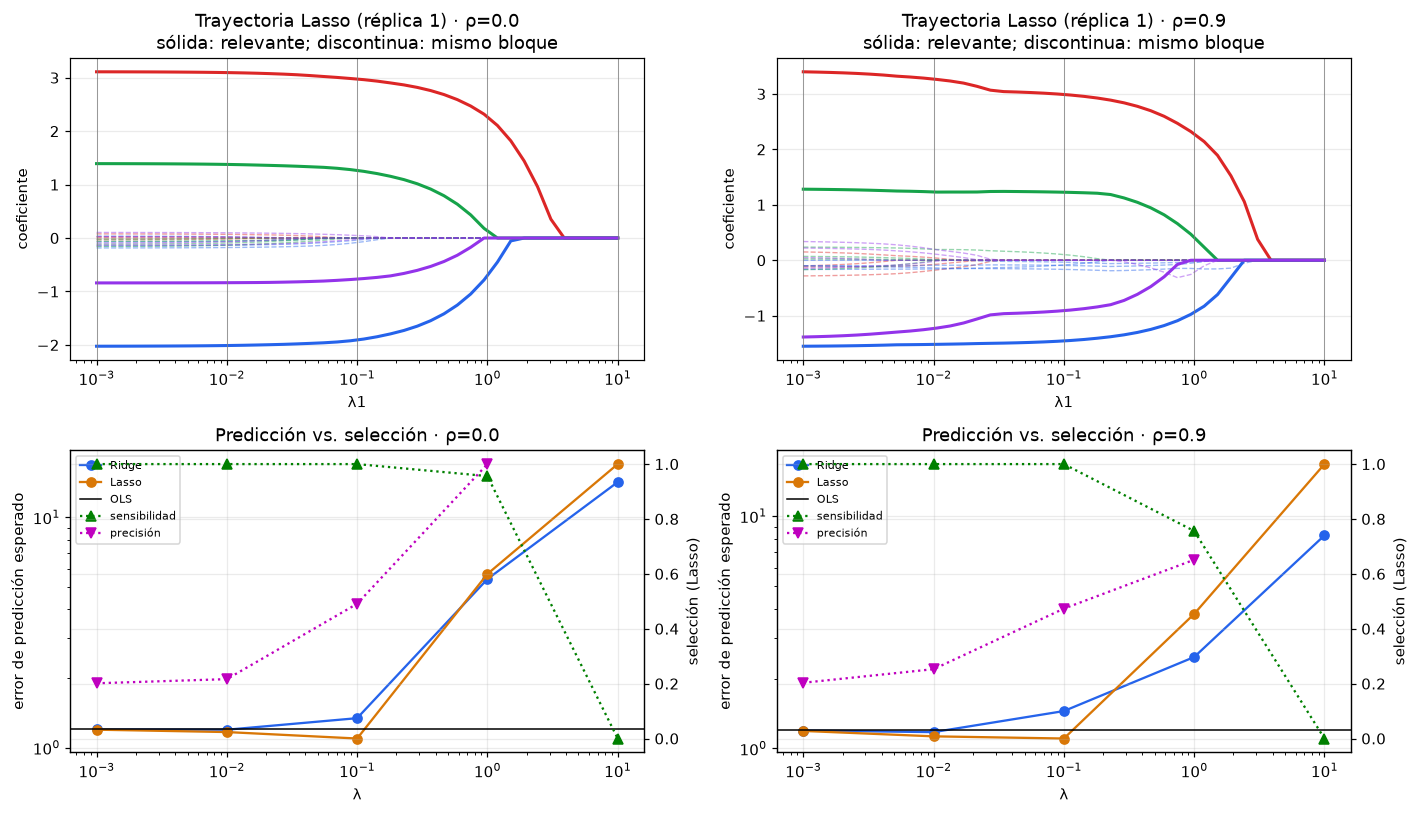

In [14]:
lam_path = np.logspace(-3, 1, 40)
colores = {0: "#dc2626", 5: "#2563eb", 10: "#16a34a", 15: "#9333ea"}
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for col, rho in enumerate(RHOS):
    X, Xs, Y = generar_escenario(rho)
    # trayectoria de coeficientes: de lambda grande a pequeño, con arranque en caliente (warm_start)
    m = LassoRegression(lam1=lam_path[-1], fit_intercept=False, accelerate=True, tol=1e-9, warm_start=True)
    camino = []
    for lam in lam_path[::-1]:
        m.lam1 = lam
        m.fit(X, Y[0])
        camino.append(m.coef_.copy())
    camino = np.array(camino[::-1])
    ax = axes[0, col]
    for j in range(D):
        relevante = j in S_STAR
        color = colores.get(j, colores[5 * BLOQUE[j]])
        if relevante:
            ax.plot(lam_path, camino[:, j], lw=2, color=color, alpha=1, ls="-")
        else:
            ax.plot(lam_path, camino[:, j], lw=0.9, color=color, alpha=0.45, ls="--")
    for lam in LAMBDAS:
        ax.axvline(lam, color="gray", lw=0.5)
    ax.set(xscale="log", xlabel="λ1", ylabel="coeficiente",
           title=f"Trayectoria Lasso (réplica 1) · ρ={rho}\nsólida: relevante; discontinua: mismo bloque")
    # abajo: error de predicción contra sensibilidad y precisión
    ax = axes[1, col]
    s = sim[sim.rho == rho]
    for modelo, color in [("Ridge", "#2563eb"), ("Lasso", "#d97706")]:
        t = s[s.modelo == modelo]
        ax.plot(t["lambda"], t["E_pred = E_f + σ²"], "-o", color=color, label=modelo)
    ax.axhline(s[s.modelo == "OLS"]["E_pred = E_f + σ²"].iloc[0], color="k", lw=1, label="OLS")
    ax2 = ax.twinx()
    t = seleccion[seleccion.rho == rho]
    ax2.plot(t["lambda"], t["sensibilidad media"], "g:^", label="sensibilidad")
    ax2.plot(t["lambda"], t["precisión media"], "m:v", label="precisión")
    ax2.set_ylim(-0.05, 1.05)
    ax2.set_ylabel("selección (Lasso)")
    ax.set(xscale="log", yscale="log", xlabel="λ", ylabel="error de predicción esperado",
           title=f"Predicción vs. selección · ρ={rho}")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
plt.tight_layout()
plt.savefig(RES / "p5_trayectorias_seleccion.png", bbox_inches="tight")
plt.show()

## Problema 5d — Respuestas con evidencia

**¿La regularización baja sesgo y varianza al mismo tiempo?** No. Al subir λ, $\hat V$ baja y el sesgo² (corregido)
sube en los dos escenarios. Las pequeñas bajadas conjuntas con λ=10⁻³ están dentro del ruido $V/R$. La regularización
**cambia** varianza por sesgo, y solo mejora el error total en un rango intermedio de λ.

**¿Predecir mejor implica encontrar las variables correctas?** No. El mejor Lasso para predecir (λ1=0.1) no acierta
nunca el soporte exacto; el que mejor acierta el soporte con ρ=0 (λ1=1, 82.5 %) predice unas 49 veces peor.

**¿Cuándo una variable irrelevante reemplaza a una relevante?** Cuando está muy correlacionada con ella (ρ=0.9 dentro
del bloque): en la muestra $x_j\approx x_1$, así que $w_jx_j$ aporta casi lo mismo con una penalización parecida.
Con λ1=1 pasa ≈1 vez por réplica. La variable es irrelevante en el modelo verdadero ($w^\star_j=0$) pero útil para
predecir; por eso la selección de Lasso cambia entre réplicas y no se debe leer como "causas".

In [15]:
resumen = sim.pivot_table(index=["modelo", "lambda"], columns="rho", values=["B2", "V", "E_f"])
display(resumen.round(4))
print(f"Tiempo total del notebook: {time.time() - T0:.1f} s")

B2               E_f                V        
rho                0.0      0.9      0.0      0.9     0.0     0.9
modelo lambda                                                    
Lasso  0.001    0.0067   0.0036   0.1979   0.1900  0.1913  0.1864
       0.010    0.0058   0.0046   0.1697   0.1278  0.1638  0.1232
       0.100    0.0432   0.0496   0.0963   0.1037  0.0532  0.0541
       1.000    4.6505   2.7618   4.6827   2.7941  0.0321  0.0323
       10.000  16.0484  15.7579  16.0484  15.7579  0.0000  0.0000
OLS    0.000    0.0068   0.0044   0.2014   0.2000  0.1946  0.1956
Ridge  0.001    0.0067   0.0034   0.2008   0.1947  0.1940  0.1913
       0.010    0.0081   0.0159   0.1973   0.1759  0.1891  0.1601
       0.100    0.1940   0.3843   0.3438   0.4490  0.1498  0.0646
       1.000    4.3621   1.4542   4.4006   1.4751  0.0385  0.0209
       10.000  13.2405   7.2624  13.2418   7.2651  0.0013  0.0027

Tiempo total del notebook: 5.7 s
